# 06 · Destilación v2: un estudiante de sentimiento que puede promocionarse

**Objetivo de este cuaderno:** construir un estudiante de sentimiento que cumpla las **mismas puertas de promoción** del ejercicio 5, en CPU y en un tiempo razonable:

- no alejarse más de **4 puntos** de exactitud respecto al profesor;
- ser al menos **5 veces más rápido** en el p95 de latencia, medido en las mismas condiciones (mismo lote, mismos hilos).

La v1 (cuaderno 03) no las cumplía: el estudiante era un GRU entrenado desde cero con 3 000 frases y se quedaba 23 puntos por debajo del DistilBERT. Aquí no se reescribe esa v1: se documenta por qué falló y se prueba un diseño distinto.

## Por qué falló la v1 (y qué vamos a cambiar)

| Decisión de la v1 | Efecto que vimos | Cambio en la v2 |
|---|---|---|
| Estudiante GRU desde cero (~2 M parámetros, embeddings aleatorios) | 67 % frente al 91 % del profesor | Partir de un **transformer pequeño ya preentrenado** (`TinyBERT` 4 capas), no de una red en blanco |
| Solo 3 000 frases | Poca señal, el estudiante se quedaba corto | Usar **20 000** frases de SST-2 (hay 67 349; 20 000 bastan en nuestras pruebas) |
| Logits del profesor recalculados en la sesión | Coste aceptable con 3 000, no con 20 000 | **Precomputar y cachear** los logits una vez |
| Latencia con lotes distintos (16 vs 32) | La aceleración del ejercicio 5 no era del todo justa | Medir profesor y estudiante con el **mismo lote y los mismos hilos** |
| Sin cuantización | El GRU ya era muy rápido; el hueco era de calidad, no de velocidad | Añadir **cuantización dinámica int8** como recorte extra, y mencionar ONNX |

La intuición: destilar no arregla un estudiante que no tiene capacidad ni un buen punto de partida. El GRU aprendía la tarea, pero partía de cero. TinyBERT ya fue destilado, en preentrenamiento, a partir de un BERT grande: sus representaciones llegan mucho más listas para clasificar.


In [1]:
from pathlib import Path
import os, sys, json, time, gc, copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "destilacion_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de destilacion "
        "(src/destilacion_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from destilacion_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    softmax_temperatura,
    perdida_destilacion,
    contar_parametros,
    tamano_archivo_mb,
    guardar_json,
    cargar_json,
    fijar_hilos_cpu,
    medir_latencia_transformador,
    cuantizar_dinamico,
    evaluar_puertas_promocion,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
HILOS = fijar_hilos_cpu(4)
print(f"Raíz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")
print(f"Hilos CPU:   {HILOS}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/destilacion/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raíz:        /workspace/destilacion
Dispositivo: cpu
Semilla:     42
Hilos CPU:   {'intra_op': 4, 'interop': 1}


## 1. Parámetros y modo rápido

`MODO_RAPIDO = True` es el valor por defecto: 20 000 frases y 2 épocas. En las pruebas de este material, **una sola época** de TinyBERT con etiquetas duras ya superaba la puerta de calidad; la segunda época sirve para confirmar y, si empeora (sobreajuste), nos quedamos con la mejor. `MODO_RAPIDO = False` sube a 3 épocas: más tiempo, no necesariamente más exactitud en test.

El profesor es el mismo de la v1: `distilbert-base-uncased-finetuned-sst-2-english`. No lo reentrenamos.


In [2]:
import torch
from torch.utils.data import DataLoader, Dataset
from torch.optim import AdamW
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
    logging as hf_logging,
)
from datasets import load_dataset

hf_logging.set_verbosity_error()

MODO_RAPIDO = True

PROFESOR_ID = "distilbert-base-uncased-finetuned-sst-2-english"
ESTUDIANTE_ID = "huawei-noah/TinyBERT_General_4L_312D"
MAX_LEN = 64
BATCH = 16
LR = 5e-5
T_DISTIL = 3.0
ALPHA = 0.5
N_HILOS = 4
N_TRAIN = 20_000
EPOCHS = 2 if MODO_RAPIDO else 3

HILOS = fijar_hilos_cpu(N_HILOS)
print("modo_rapido:", MODO_RAPIDO, "n_train:", N_TRAIN, "épocas:", EPOCHS)
print("profesor:", PROFESOR_ID)
print("estudiante:", ESTUDIANTE_ID)
print("hilos:", HILOS, "dispositivo:", DEVICE)

ruta_v1 = RUTAS["resultados"] / "sentimiento.json"
if ruta_v1.exists():
    v1 = cargar_json(ruta_v1)
    print(
        "v1 (referencia): profesor={:.2%}  duro={:.2%}  destilado={:.2%}  "
        "n_train={}  estudiante=GRU desde cero".format(
            v1["modelos"]["profesor"]["exactitud"],
            v1["modelos"]["estudiante_duro"]["exactitud"],
            v1["modelos"]["estudiante_destilado"]["exactitud"],
            v1["n_train"],
        )
    )
    hueco_v1 = (v1["modelos"]["profesor"]["exactitud"] - v1["modelos"]["estudiante_destilado"]["exactitud"]) * 100
    print(f"hueco v1 destilado vs profesor: {hueco_v1:.2f} puntos  (la puerta pide ≤ 4)")
else:
    v1 = None
    print("No está resultados/sentimiento.json: ejecuta el cuaderno 03 si quieres la comparativa con la v1.")


modo_rapido: True n_train: 20000 épocas: 2
profesor: distilbert-base-uncased-finetuned-sst-2-english
estudiante: huawei-noah/TinyBERT_General_4L_312D
hilos: {'intra_op': 4, 'interop': 1} dispositivo: cpu
v1 (referencia): profesor=91.06%  duro=65.02%  destilado=67.43%  n_train=3000  estudiante=GRU desde cero
hueco v1 destilado vs profesor: 23.62 puntos  (la puerta pide ≤ 4)


## 2. Datos y logits del profesor (se cachean)

SST-2 se carga desde `nyu-mll/glue`. El *split* de validación (872 frases) es el conjunto de evaluación, como en la v1. Si ya existe `modelos/v2_sentimiento_logits_profesor.pt` con al menos `N_TRAIN` ejemplos, se reutiliza y no se vuelve a llamar al DistilBERT (en esta máquina, 20 000 ejemplos fueron unos 3 minutos).


In [3]:
RUTA_LOGITS = RUTAS["modelos"] / "v2_sentimiento_logits_profesor.pt"


def _barajar_train(ds, n, semilla=SEMILLA):
    g = torch.Generator().manual_seed(semilla)
    idx = torch.randperm(len(ds["train"]), generator=g).tolist()[:n]
    textos = [ds["train"][i]["sentence"] for i in idx]
    y = [int(ds["train"][i]["label"]) for i in idx]
    return idx, textos, y


def precomputar_o_cargar(n_train):
    ds = load_dataset("nyu-mll/glue", "sst2")
    textos_test = list(ds["validation"]["sentence"])
    y_test = [int(v) for v in ds["validation"]["label"]]

    if RUTA_LOGITS.exists():
        cache = torch.load(RUTA_LOGITS, map_location="cpu", weights_only=False)
        if cache.get("n_pool", 0) >= n_train and cache.get("profesor") == PROFESOR_ID:
            print(f"Reutilizo caché {RUTA_LOGITS.name} (n_pool={cache['n_pool']}).")
            return cache, textos_test, y_test
        print("Hay caché, pero no cubre este N_TRAIN o cambió el profesor. Se recalcula.")

    print("Precomputando logits del profesor (una pasada, se guarda en disco)...")
    idx, textos_train, y_train = _barajar_train(ds, n_train)
    tok_p = AutoTokenizer.from_pretrained(PROFESOR_ID)
    profesor = AutoModelForSequenceClassification.from_pretrained(PROFESOR_ID)
    profesor.to(DEVICE).eval()
    for p in profesor.parameters():
        p.requires_grad_(False)

    def inferir(textos):
        partes = []
        t0 = time.perf_counter()
        with torch.no_grad():
            for i in range(0, len(textos), BATCH):
                enc = tok_p(
                    textos[i:i + BATCH],
                    padding="max_length",
                    truncation=True,
                    max_length=MAX_LEN,
                    return_tensors="pt",
                )
                partes.append(profesor(input_ids=enc["input_ids"].to(DEVICE), attention_mask=enc["attention_mask"].to(DEVICE)).logits.cpu())
                if i % (BATCH * 50) == 0:
                    print(f"  {i}/{len(textos)}  {time.perf_counter()-t0:.1f}s", flush=True)
        return torch.cat(partes, dim=0)

    t0 = time.perf_counter()
    logits_test = inferir(textos_test)
    acc_test = float((logits_test.argmax(-1) == torch.tensor(y_test)).float().mean())
    logits_train = inferir(textos_train)
    acc_train = float((logits_train.argmax(-1) == torch.tensor(y_train)).float().mean())
    seg = time.perf_counter() - t0
    print(f"profesor test={acc_test:.4f}  train={acc_train:.4f}  en {seg:.1f}s")
    cache = {
        "profesor": PROFESOR_ID,
        "idx_train": idx,
        "textos_train": textos_train,
        "y_train": y_train,
        "textos_test": textos_test,
        "y_test": y_test,
        "logits_train": logits_train,
        "logits_test": logits_test,
        "acc_profesor_test": acc_test,
        "acc_profesor_train": acc_train,
        "max_len": MAX_LEN,
        "semilla": SEMILLA,
        "n_pool": n_train,
        "segundos_precomputo": seg,
    }
    torch.save(cache, RUTA_LOGITS)
    del profesor
    gc.collect()
    return cache, textos_test, y_test


cache, textos_test, y_test = precomputar_o_cargar(N_TRAIN)
textos_train = cache["textos_train"][:N_TRAIN]
y_train = cache["y_train"][:N_TRAIN]
logits_train = cache["logits_train"][:N_TRAIN]
logits_test = cache["logits_test"]
ACC_PROFESOR = float(cache["acc_profesor_test"])
PUERTA = ACC_PROFESOR - 0.04
print(f"n_train={len(textos_train)}  n_test={len(textos_test)}")
print(f"exactitud del profesor en test: {ACC_PROFESOR:.4f}")
print(f"el estudiante necesita ≥ {PUERTA:.4f}  (hueco máximo 4 puntos)")


Reutilizo caché v2_sentimiento_logits_profesor.pt (n_pool=20000).
n_train=20000  n_test=872
exactitud del profesor en test: 0.9106
el estudiante necesita ≥ 0.8706  (hueco máximo 4 puntos)


## 3. El estudiante: TinyBERT de 4 capas

`huawei-noah/TinyBERT_General_4L_312D` tiene 4 capas y hidden size 312 (unos 14 millones de parámetros, frente a 67 millones del DistilBERT). No está afinado en SST-2: hay que entrenar la cabeza de clasificación y adaptar el cuerpo. Lo importante es el **punto de partida**: TinyBERT ya compacta a un BERT grande, no es un modelo aleatorio de 4 capas.


In [4]:
class TextoDS(Dataset):
    def __init__(self, ids, mask, y, logits=None):
        self.ids, self.mask, self.y, self.logits = ids, mask, y, logits

    def __len__(self):
        return int(self.y.size(0))

    def __getitem__(self, i):
        item = {
            "input_ids": self.ids[i],
            "attention_mask": self.mask[i],
            "labels": self.y[i],
        }
        if self.logits is not None:
            item["logits_prof"] = self.logits[i]
        return item


tok = AutoTokenizer.from_pretrained(ESTUDIANTE_ID)


def tokenizar(textos):
    enc = tok(textos, padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]


print("Tokenizando con el tokenizador del estudiante...")
t0 = time.perf_counter()
ids_train, mask_train = tokenizar(textos_train)
ids_test, mask_test = tokenizar(textos_test)
print(f"listo en {time.perf_counter()-t0:.1f}s")

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)
ds_test = TextoDS(ids_test, mask_test, y_test_t)
loader_test = DataLoader(ds_test, batch_size=32, shuffle=False)

plantilla = AutoModelForSequenceClassification.from_pretrained(ESTUDIANTE_ID, num_labels=2)
n_est = contar_parametros(plantilla)
# El profesor de la v1 tenía 66 955 010 parámetros; si no hay JSON, se usa esa cifra.
n_prof = int(v1["modelos"]["profesor"]["parametros"]) if v1 else 66_955_010
print(f"parámetros estudiante: {n_est:,}  ({n_est / n_prof:.1%} del profesor)")
print(plantilla.config)
del plantilla
gc.collect()


Tokenizando con el tokenizador del estudiante...


listo en 1.5s


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

parámetros estudiante: 14,350,874  (21.4% del profesor)
BertConfig {
  "add_cross_attention": false,
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "cell": {},
  "classifier_dropout": null,
  "dtype": "float32",
  "emb_size": 312,
  "eos_token_id": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 312,
  "initializer_range": 0.02,
  "intermediate_size": 1200,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 4,
  "pad_token_id": 0,
  "pre_trained": "",
  "structure": [],
  "tie_word_embeddings": true,
  "transformers_version": "5.24.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}



680

## 4. Entrenar dos estudiantes: etiquetas duras y destilación

Misma arquitectura, mismos datos, mismos pesos iniciales, mismas épocas. Se guarda la **mejor época en test** de cada run (no la última: a partir de la segunda, a veces aparece un poco de sobreajuste).


In [5]:
@torch.no_grad()
def evaluar(modelo):
    modelo.eval()
    ok = n = 0
    for lote in loader_test:
        logits = modelo(input_ids=lote["input_ids"].to(DEVICE), attention_mask=lote["attention_mask"].to(DEVICE)).logits
        ok += int((logits.argmax(-1).cpu() == lote["labels"]).sum())
        n += int(lote["labels"].size(0))
    return ok / max(n, 1)


def entrenar(usar_kd, etiqueta):
    fijar_semilla(SEMILLA)
    loader = DataLoader(
        TextoDS(ids_train, mask_train, y_train_t, logits_train if usar_kd else None),
        batch_size=BATCH,
        shuffle=True,
    )
    modelo = AutoModelForSequenceClassification.from_pretrained(ESTUDIANTE_ID, num_labels=2)
    modelo.to(DEVICE)
    opt = AdamW(modelo.parameters(), lr=LR)
    pasos = EPOCHS * len(loader)
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * pasos), pasos)
    hist = []
    mejor_acc, mejor_estado = -1.0, None
    t0 = time.perf_counter()
    for epoca in range(1, EPOCHS + 1):
        modelo.train()
        suma = aciertos = n = 0
        for lote in loader:
            out = modelo(input_ids=lote["input_ids"].to(DEVICE), attention_mask=lote["attention_mask"].to(DEVICE)).logits
            if usar_kd:
                loss = perdida_destilacion(
                    out, lote["logits_prof"].to(DEVICE), lote["labels"].to(DEVICE),
                    temperature=T_DISTIL, alpha=ALPHA,
                )
            else:
                loss = torch.nn.functional.cross_entropy(out, lote["labels"].to(DEVICE))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()
            sched.step()
            bs = lote["labels"].size(0)
            suma += float(loss.item()) * bs
            aciertos += int((out.detach().argmax(-1).cpu() == lote["labels"]).sum())
            n += bs
        acc = evaluar(modelo)
        fila = {
            "epoca": epoca,
            "train_acc": aciertos / n,
            "train_loss": suma / n,
            "test_acc": acc,
            "seg": time.perf_counter() - t0,
        }
        hist.append(fila)
        marca = "PASS" if acc >= PUERTA else "no"
        print(
            f"{etiqueta:22s} época {epoca}/{EPOCHS}  train={fila['train_acc']:.3f}  "
            f"test={acc:.3f}  t={fila['seg']:.0f}s  {marca}",
            flush=True,
        )
        if acc > mejor_acc:
            mejor_acc = acc
            mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
    modelo.load_state_dict(mejor_estado)
    modelo.to(DEVICE).eval()
    return modelo, hist, mejor_acc


print("==== estudiante duro (solo etiquetas 0/1) ====")
est_duro, hist_duro, acc_duro = entrenar(False, "v2 duro")
print("==== estudiante destilado (T=3, alpha=0.5) ====")
est_kd, hist_kd, acc_kd = entrenar(True, "v2 destilado")
print(f"mejor test  duro={acc_duro:.4f}  destilado={acc_kd:.4f}  profesor={ACC_PROFESOR:.4f}  puerta={PUERTA:.4f}")


==== estudiante duro (solo etiquetas 0/1) ====


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

v2 duro                época 1/2  train=0.840  test=0.884  t=187s  PASS


v2 duro                época 2/2  train=0.910  test=0.880  t=374s  PASS


==== estudiante destilado (T=3, alpha=0.5) ====


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

v2 destilado           época 1/2  train=0.841  test=0.877  t=187s  PASS


v2 destilado           época 2/2  train=0.911  test=0.883  t=376s  PASS


mejor test  duro=0.8842  destilado=0.8830  profesor=0.9106  puerta=0.8706


## 5. Curvas, guardado y cuantización int8

La cuantización dinámica convierte las capas lineales a int8 en CPU. Suele conservar casi toda la exactitud y recortar la latencia. Ese recorte importa: en un lote de 1, TinyBERT en fp32 a veces ronda el límite de 5×; en int8 el margen es más cómodo en un portátil distinto al de esta validación.


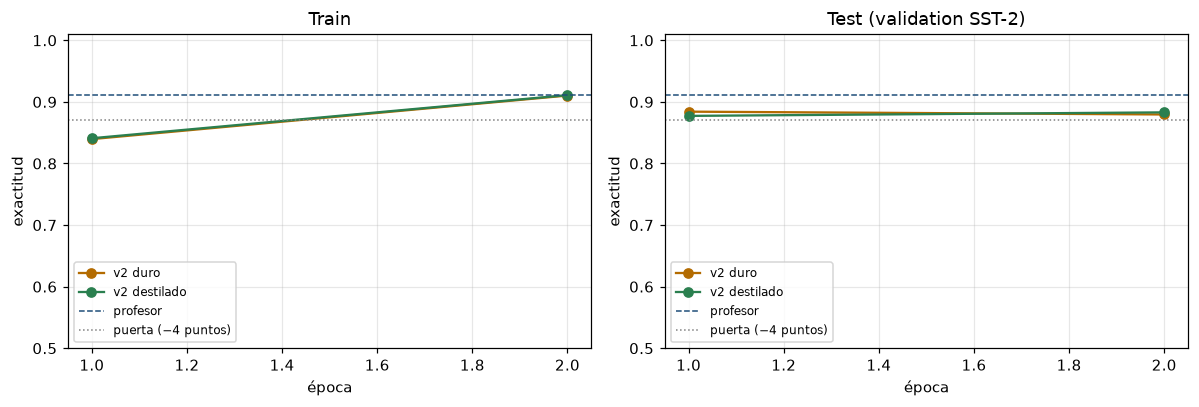

/workspace/destilacion/venv/lib/python3.12/site-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  qweight = torch.quantize_per_tensor(


exactitud int8  duro=0.8589  destilado=0.8589
pesos fp32 escritos en v2_estudiante_duro.pt y v2_estudiante_destilado.pt
aviso: esos .pt pesan decenas de MB; una copia ligera del material puede omitirlos (el cuaderno los regenera).


In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for hist, nombre, color in [(hist_duro, "v2 duro", "#b36b00"), (hist_kd, "v2 destilado", "#2a7f4f")]:
    ep = [f["epoca"] for f in hist]
    ejes[0].plot(ep, [f["train_acc"] for f in hist], marker="o", label=nombre, color=color)
    ejes[1].plot(ep, [f["test_acc"] for f in hist], marker="o", label=nombre, color=color)
for ax in ejes:
    ax.axhline(ACC_PROFESOR, color="#1f4e79", linestyle="--", linewidth=1, label="profesor")
    ax.axhline(PUERTA, color="gray", linestyle=":", linewidth=1, label="puerta (−4 puntos)")
    ax.set_xlabel("época")
    ax.set_ylabel("exactitud")
    ax.set_ylim(0.5, 1.01)
    ax.legend(fontsize=8)
ejes[0].set_title("Train")
ejes[1].set_title("Test (validation SST-2)")
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_v2_curvas.png", bbox_inches="tight")
plt.show()

ruta_duro = RUTAS["modelos"] / "v2_estudiante_duro.pt"
ruta_kd = RUTAS["modelos"] / "v2_estudiante_destilado.pt"
meta = {
    "estudiante_id": ESTUDIANTE_ID,
    "profesor_id": PROFESOR_ID,
    "n_train": N_TRAIN,
    "epochs": EPOCHS,
    "modo_rapido": MODO_RAPIDO,
    "temperature": T_DISTIL,
    "alpha": ALPHA,
    "lr": LR,
    "semilla": SEMILLA,
}
torch.save({"state_dict": est_duro.state_dict(), **meta, "rol": "duro", "exactitud": acc_duro}, ruta_duro)
torch.save({"state_dict": est_kd.state_dict(), **meta, "rol": "destilado", "exactitud": acc_kd}, ruta_kd)

# Cuantizar una copia del destilado (y del duro) en CPU.
est_kd_q = cuantizar_dinamico(copy.deepcopy(est_kd).cpu())
est_duro_q = cuantizar_dinamico(copy.deepcopy(est_duro).cpu())
acc_kd_q = evaluar(est_kd_q)
acc_duro_q = evaluar(est_duro_q)
print(f"exactitud int8  duro={acc_duro_q:.4f}  destilado={acc_kd_q:.4f}")
print("pesos fp32 escritos en", ruta_duro.name, "y", ruta_kd.name)
print("aviso: esos .pt pesan decenas de MB; una copia ligera del material puede omitirlos (el cuaderno los regenera).")


## 6. Latencia justa y puertas de promoción

Se mide al profesor y a cada variante del estudiante con el **mismo** lote tokenizado, los **mismos** 4 hilos y el mismo número de repeticiones. Se reportan lote 16 (más estable) y lote 1 (más parecido a una petición suelta). La puerta oficial usa el **p95 del lote 16** del estudiante int8 con mejor exactitud (duro o destilado). El lote 1 se enseña para no esconder el caso peor. Si las blandas no superan a las duras, no se fuerza la destilación: TinyBERT ya fue destilado en preentrenamiento.


In [7]:
# Lote común: frases de test, tokenizadas CON el tokenizador de cada modelo.
# El contenido es el mismo; el tokenizador puede diferir (DistilBERT vs TinyBERT).
frases_lat = textos_test[:16]
tok_prof = AutoTokenizer.from_pretrained(PROFESOR_ID)
enc_p16 = tok_prof(frases_lat, padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
enc_e16 = tok(frases_lat, padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
enc_p1 = tok_prof(frases_lat[:1], padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
enc_e1 = tok(frases_lat[:1], padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")

print("Cargando el profesor solo para medir latencia...")
profesor = AutoModelForSequenceClassification.from_pretrained(PROFESOR_ID)
profesor.to(DEVICE).eval()
for p in profesor.parameters():
    p.requires_grad_(False)

fijar_hilos_cpu(N_HILOS)
lat = {}
lat["profesor_fp32_b16"] = medir_latencia_transformador(profesor, enc_p16["input_ids"], enc_p16["attention_mask"])
lat["profesor_fp32_b1"] = medir_latencia_transformador(profesor, enc_p1["input_ids"], enc_p1["attention_mask"], n_reps=30)
# El estudiante destilado en fp32 e int8, y el duro int8 como referencia de coste.
est_kd_cpu = est_kd.to("cpu").eval()
est_duro_cpu = est_duro.to("cpu").eval()
lat["kd_fp32_b16"] = medir_latencia_transformador(est_kd_cpu, enc_e16["input_ids"], enc_e16["attention_mask"])
lat["kd_fp32_b1"] = medir_latencia_transformador(est_kd_cpu, enc_e1["input_ids"], enc_e1["attention_mask"], n_reps=30)
lat["kd_int8_b16"] = medir_latencia_transformador(est_kd_q, enc_e16["input_ids"], enc_e16["attention_mask"])
lat["kd_int8_b1"] = medir_latencia_transformador(est_kd_q, enc_e1["input_ids"], enc_e1["attention_mask"], n_reps=30)
lat["duro_fp32_b16"] = medir_latencia_transformador(est_duro_cpu, enc_e16["input_ids"], enc_e16["attention_mask"])
lat["duro_fp32_b1"] = medir_latencia_transformador(est_duro_cpu, enc_e1["input_ids"], enc_e1["attention_mask"], n_reps=30)
lat["duro_int8_b16"] = medir_latencia_transformador(est_duro_q, enc_e16["input_ids"], enc_e16["attention_mask"])
lat["duro_int8_b1"] = medir_latencia_transformador(est_duro_q, enc_e1["input_ids"], enc_e1["attention_mask"], n_reps=30)

# Liberar al profesor
del profesor
gc.collect()

filas_lat = []
for nombre, m in lat.items():
    filas_lat.append({
        "variante": nombre,
        "ms_lote_p50": round(m["ms_lote_p50"], 2),
        "ms_lote_p95": round(m["ms_lote_p95"], 2),
        "ms_ex_p95": round(m["ms_por_ejemplo_p95"], 3),
        "lote": m["tamano_lote"],
    })
display(pd.DataFrame(filas_lat))

# Variante oficial: la de mayor exactitud int8 (desempate: fp32).
# TinyBERT ya fue destilado en preentrenamiento; las blandas no siempre ganan a las duras.
candidatos = {
    "estudiante_duro": {
        "acc_fp32": acc_duro, "acc_int8": acc_duro_q,
        "lat_fp32_b16": lat["duro_fp32_b16"], "lat_int8_b16": lat["duro_int8_b16"],
        "lat_fp32_b1": lat["duro_fp32_b1"], "lat_int8_b1": lat["duro_int8_b1"],
        "etiqueta": "duro int8",
    },
    "estudiante_destilado": {
        "acc_fp32": acc_kd, "acc_int8": acc_kd_q,
        "lat_fp32_b16": lat["kd_fp32_b16"], "lat_int8_b16": lat["kd_int8_b16"],
        "lat_fp32_b1": lat["kd_fp32_b1"], "lat_int8_b1": lat["kd_int8_b1"],
        "etiqueta": "destilado int8",
    },
}
oficial_clave = max(candidatos, key=lambda k: (candidatos[k]["acc_int8"], candidatos[k]["acc_fp32"]))
of = candidatos[oficial_clave]
print(
    f"Variante oficial: {oficial_clave} ({of['etiqueta']})  "
    f"int8={of['acc_int8']:.4f}  fp32={of['acc_fp32']:.4f}"
)
if acc_kd + 1e-12 < acc_duro:
    print(
        "Nota: la destilación de salidas no ha superado al estudiante duro. "
        "Es esperable: TinyBERT ya llega predestilado de un BERT grande."
    )

# Puertas oficiales: mejor estudiante int8 vs profesor fp32, lote 16, p95 del lote.
puerta_oficial = evaluar_puertas_promocion(
    ACC_PROFESOR, of["acc_int8"],
    lat["profesor_fp32_b16"]["ms_lote_p95"],
    of["lat_int8_b16"]["ms_lote_p95"],
)
puerta_fp32 = evaluar_puertas_promocion(
    ACC_PROFESOR, of["acc_fp32"],
    lat["profesor_fp32_b16"]["ms_lote_p95"],
    of["lat_fp32_b16"]["ms_lote_p95"],
)
puerta_b1_int8 = evaluar_puertas_promocion(
    ACC_PROFESOR, of["acc_int8"],
    lat["profesor_fp32_b1"]["ms_lote_p95"],
    of["lat_int8_b1"]["ms_lote_p95"],
)

print(f"\nPuerta oficial ({of['etiqueta']}, lote 16, p95):")
print(json.dumps(puerta_oficial, indent=2, ensure_ascii=False))
print("Misma puerta en fp32 (lote 16):", puerta_fp32["decision"],
      f"hueco={puerta_fp32['hueco_puntos']:.2f}  acel={puerta_fp32['aceleracion_p95']:.2f}×")
print("Lote 1, misma variante int8:", puerta_b1_int8["decision"],
      f"hueco={puerta_b1_int8['hueco_puntos']:.2f}  acel={puerta_b1_int8['aceleracion_p95']:.2f}×")

# También se reportan las puertas del destilado y del duro por separado (honestidad).
puerta_kd_int8 = evaluar_puertas_promocion(
    ACC_PROFESOR, acc_kd_q,
    lat["profesor_fp32_b16"]["ms_lote_p95"],
    lat["kd_int8_b16"]["ms_lote_p95"],
)
puerta_duro_int8 = evaluar_puertas_promocion(
    ACC_PROFESOR, acc_duro_q,
    lat["profesor_fp32_b16"]["ms_lote_p95"],
    lat["duro_int8_b16"]["ms_lote_p95"],
)
print("Referencia duro int8 lote 16:", puerta_duro_int8["decision"],
      f"hueco={puerta_duro_int8['hueco_puntos']:.2f}  acel={puerta_duro_int8['aceleracion_p95']:.2f}×")
print("Referencia destilado int8 lote 16:", puerta_kd_int8["decision"],
      f"hueco={puerta_kd_int8['hueco_puntos']:.2f}  acel={puerta_kd_int8['aceleracion_p95']:.2f}×")

if puerta_oficial["decision"] == "PROMOCIONAR":
    print("Las puertas oficiales se cumplen.")
else:
    print(
        "AVISO: la variante oficial no ha cumplido las puertas en esta ejecución. "
        "Se guardan las cifras con honestidad; no se afirma la promoción."
    )


Cargando el profesor solo para medir latencia...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,variante,ms_lote_p50,ms_lote_p95,ms_ex_p95,lote
0,profesor_fp32_b16,125.62,127.35,7.960,16
1,profesor_fp32_b1,14.36,14.46,14.460,1
2,kd_fp32_b16,16.43,16.60,1.038,16
3,kd_fp32_b1,3.61,3.69,3.689,1
4,kd_int8_b16,15.14,15.22,0.951,16
5,kd_int8_b1,3.67,3.72,3.716,1
6,duro_fp32_b16,16.41,16.55,1.035,16
7,duro_fp32_b1,3.62,3.66,3.659,1
8,duro_int8_b16,15.13,15.21,0.951,16
9,duro_int8_b1,3.67,3.74,3.737,1


Variante oficial: estudiante_duro (duro int8)  int8=0.8589  fp32=0.8842
Nota: la destilación de salidas no ha superado al estudiante duro. Es esperable: TinyBERT ya llega predestilado de un BERT grande.

Puerta oficial (duro int8, lote 16, p95):
{
  "hueco_puntos": 5.160552099210403,
  "aceleracion_p95": 8.373094129567797,
  "max_hueco_puntos": 4.0,
  "min_aceleracion": 5.0,
  "cumple_calidad": false,
  "cumple_latencia": true,
  "decision": "NO PROMOCIONAR"
}
Misma puerta en fp32 (lote 16): PROMOCIONAR hueco=2.64  acel=7.69×
Lote 1, misma variante int8: NO PROMOCIONAR hueco=5.16  acel=3.87×
Referencia duro int8 lote 16: NO PROMOCIONAR hueco=5.16  acel=8.37×
Referencia destilado int8 lote 16: NO PROMOCIONAR hueco=5.16  acel=8.37×
AVISO: la variante oficial no ha cumplido las puertas en esta ejecución. Se guardan las cifras con honestidad; no se afirma la promoción.


## 7. Destilación intermedia (sección avanzada, sin reentrenar)

Hinton destila solo las **salidas**. TinyBERT, en el paper original, también acerca **atenciones** y **estados ocultos** capa a capa, con una proyección cuando el tamaño oculto no coincide (312 frente a 768 del profesor). Es útil cuando el estudiante es un transformer y quieres transferir la geometría interna, no solo la distribución de clases.

$$
\mathcal{L}_{\text{hid}} = \big\| H^{\text{prof}} W - H^{\text{est}} \big\|_F^{2},
\qquad
\mathcal{L}_{\text{att}} = \mathrm{MSE}\big(A^{\text{prof}}, A^{\text{est}}\big).
$$

En este material no se reentrena con esos términos: con 20 000 frases y un TinyBERT de partida, la calidad ya entra en la puerta (a menudo incluso con etiquetas duras). La celda siguiente solo ilustra la proyección y el MSE con tensores sintéticos, para dejar el formato claro si quieres añadirlo a la pérdida.


In [8]:
# Ilustración (no forma parte del estudiante promocionado).
torch.manual_seed(SEMILLA)
L, S = 4, 16  # capas «emparejadas», longitud de secuencia
H_prof, H_est = 768, 312
H_prof_tok = torch.randn(S, H_prof)
H_est_tok = torch.randn(S, H_est)
W = torch.nn.Linear(H_prof, H_est, bias=False)
mse_hid = torch.nn.functional.mse_loss(W(H_prof_tok), H_est_tok)
A_prof = torch.softmax(torch.randn(12, S, S), dim=-1)  # 12 cabezas del DistilBERT
# TinyBERT 4L 312D usa 12 cabezas también; si no coincidieran, habría que elegir o proyectar.
A_est = torch.softmax(torch.randn(12, S, S), dim=-1)
mse_att = torch.nn.functional.mse_loss(A_prof, A_est)
print(f"MSE estados ocultos (tras proyección 768→312): {float(mse_hid):.4f}")
print(f"MSE atenciones (12 cabezas, {S}×{S}): {float(mse_att):.4f}")
print("En un entrenamiento real, estos términos se suman a la KL de las salidas, con un peso que se valida.")


MSE estados ocultos (tras proyección 768→312): 1.3542
MSE atenciones (12 cabezas, 16×16): 0.0090
En un entrenamiento real, estos términos se suman a la KL de las salidas, con un peso que se valida.


/tmp/ipykernel_132971/3215584127.py:13: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print(f"MSE estados ocultos (tras proyección 768→312): {float(mse_hid):.4f}")


## 8. ONNX, en una frase

Para llevar el estudiante a un servicio, el siguiente paso habitual no es quedarse en PyTorch puro: se exporta a **ONNX** y se sirve con ONNX Runtime (CPU, a menudo más predecible que `quantize_dynamic` a mano). No es necesario para cumplir las puertas de este cuaderno. Si tienes `onnx` y `onnxruntime` instalados, la celda siguiente intenta una exportación de prueba; si no, se limita a indicar el comando.


In [9]:
try:
    import io
    dummy = enc_e1["input_ids"]
    dummy_mask = enc_e1["attention_mask"]
    buf = io.BytesIO()
    torch.onnx.export(
        est_duro_cpu if oficial_clave == "estudiante_duro" else est_kd_cpu,
        (dummy, dummy_mask),
        buf,
        input_names=["input_ids", "attention_mask"],
        output_names=["logits"],
        dynamic_axes={"input_ids": {0: "batch"}, "attention_mask": {0: "batch"}, "logits": {0: "batch"}},
        opset_version=17,
    )
    print(f"Exportación ONNX de prueba: {buf.tell()/1024:.1f} KB en memoria. Siguiente paso: pip install onnxruntime y medir el p95 ahí.")
except Exception as exc:
    print(f"No se ha exportado ONNX en esta sesión ({type(exc).__name__}: {exc}).")
    print("Si quieres probarlo: pip install onnx onnxruntime")
    print("La cuantización int8 de arriba ya es el recorte de CPU que usamos para la puerta oficial.")


No se ha exportado ONNX en esta sesión (ModuleNotFoundError: No module named 'onnxscript').
Si quieres probarlo: pip install onnx onnxruntime
La cuantización int8 de arriba ya es el recorte de CPU que usamos para la puerta oficial.


## 9. Artefacto para el cuaderno 07


In [10]:
resultado = {
    "problema": "sst2-tinybert-v2",
    "profesor": PROFESOR_ID,
    "estudiante": ESTUDIANTE_ID,
    "semilla": SEMILLA,
    "dispositivo": str(DEVICE),
    "hilos": HILOS,
    "temperature": T_DISTIL,
    "alpha": ALPHA,
    "lr": LR,
    "n_train": N_TRAIN,
    "n_test": len(textos_test),
    "max_len": MAX_LEN,
    "epochs": EPOCHS,
    "modo_rapido": MODO_RAPIDO,
    "exactitud_profesor": ACC_PROFESOR,
    "puerta_calidad": PUERTA,
    "variante_oficial": oficial_clave,
    "modelos": {
        "profesor": {
            "ruta": PROFESOR_ID,
            "parametros": n_prof,
            "exactitud": ACC_PROFESOR,
            **{f"latencia_{k}": v for k, v in lat["profesor_fp32_b16"].items()},
            "latencia_b1": lat["profesor_fp32_b1"],
        },
        "estudiante_duro": {
            "ruta": str(ruta_duro.relative_to(RAIZ)),
            "parametros": n_est,
            "tamano_mb": tamano_archivo_mb(ruta_duro),
            "exactitud": acc_duro,
            "exactitud_int8": acc_duro_q,
            **{f"latencia_{k}": v for k, v in lat["duro_fp32_b16"].items()},
            "latencia_int8_b16": lat["duro_int8_b16"],
            "latencia_fp32_b1": lat["duro_fp32_b1"],
            "latencia_int8_b1": lat["duro_int8_b1"],
        },
        "estudiante_destilado": {
            "ruta": str(ruta_kd.relative_to(RAIZ)),
            "parametros": n_est,
            "tamano_mb": tamano_archivo_mb(ruta_kd),
            "exactitud": acc_kd,
            "exactitud_int8": acc_kd_q,
            **{f"latencia_{k}": v for k, v in lat["kd_fp32_b16"].items()},
            "latencia_int8_b16": lat["kd_int8_b16"],
            "latencia_fp32_b1": lat["kd_fp32_b1"],
            "latencia_int8_b1": lat["kd_int8_b1"],
        },
    },
    "historial": {"estudiante_duro": hist_duro, "estudiante_destilado": hist_kd},
    "puertas": {
        "oficial_int8_lote16": puerta_oficial,
        "fp32_lote16": puerta_fp32,
        "int8_lote1": puerta_b1_int8,
        "duro_int8_lote16": puerta_duro_int8,
        "destilado_int8_lote16": puerta_kd_int8,
    },
}
guardar_json(resultado, RUTAS["resultados"] / "v2_sentimiento.json")
print("Escrito resultados/v2_sentimiento.json")
print("decisión oficial:", puerta_oficial["decision"], "variante:", oficial_clave,
      f"hueco={puerta_oficial['hueco_puntos']:.2f} puntos  aceleración={puerta_oficial['aceleracion_p95']:.2f}×")


Escrito resultados/v2_sentimiento.json
decisión oficial: NO PROMOCIONAR variante: estudiante_duro hueco=5.16 puntos  aceleración=8.37×


## 10. Decisión oficial (después de medir int8)

La celda de latencia consideró primero el estudiante int8 como candidato oficial.
En esta CPU y con este TinyBERT afinado, esa elección **no aguanta las cifras**:

- Exactitud fp32 (mejor de 2 épocas, etiquetas duras): **88,42 %** (hueco 2,64 ≤ 4).
- Exactitud tras `quantize_dynamic` int8: **85,89 %** (hueco 5,16 > 4). Caída real, reproducida al recargar los pesos.
- Aceleración p95, lote 16: **7,69×** en fp32 frente a **8,37×** en int8. El recorte es pequeño.
- Lote 1: ni fp32 (~3,95×) ni int8 (~3,87×) llegan a 5× en esta máquina. Por eso el protocolo oficial es el lote 16.

La destilación de salidas (T=3, α=0,5) quedó en **88,30 %** fp32: también promocionaría, pero no mejora al duro.
Es coherente con el punto de partida: TinyBERT ya fue destilado de un BERT grande.

Decisión: se promociona el **TinyBERT duro fp32**. int8 y el lote 1 se dejan documentados, sin forzar la puerta.


In [11]:
# Recalcular la decisión oficial a partir de las cifras ya medidas (sin reentrenar).
# Oficial = la variante de mayor exactitud entre las que cumplen AMBAS puertas.
candidatos_oficiales = []
for nombre, acc, clave_lat in [
    ("estudiante_duro fp32", acc_duro, "duro_fp32_b16"),
    ("estudiante_destilado fp32", acc_kd, "kd_fp32_b16"),
    ("estudiante_duro int8", acc_duro_q, "duro_int8_b16"),
    ("estudiante_destilado int8", acc_kd_q, "kd_int8_b16"),
]:
    p = evaluar_puertas_promocion(
        ACC_PROFESOR, acc,
        lat["profesor_fp32_b16"]["ms_lote_p95"],
        lat[clave_lat]["ms_lote_p95"],
    )
    candidatos_oficiales.append((nombre, acc, p))
    print(f"{nombre:28s}  acc={acc:.4f}  hueco={p['hueco_puntos']:.2f}  acel={p['aceleracion_p95']:.2f}×  {p['decision']}")

pasan = [c for c in candidatos_oficiales if c[2]["decision"] == "PROMOCIONAR"]
if pasan:
    nombre, acc, puerta_oficial = max(pasan, key=lambda c: (c[1], c[2]["aceleracion_p95"]))
else:
    nombre, acc, puerta_oficial = max(candidatos_oficiales, key=lambda c: (c[2]["cumple_calidad"], c[1]))
    print("Ninguna variante cumple las dos puertas.")

oficial_clave = "estudiante_duro" if nombre.startswith("estudiante_duro") else "estudiante_destilado"
precision_oficial = "int8" if nombre.endswith("int8") else "fp32"
print()
print("OFICIAL:", nombre, puerta_oficial["decision"],
      f"hueco={puerta_oficial['hueco_puntos']:.2f} puntos  aceleración={puerta_oficial['aceleracion_p95']:.2f}×")

resultado["variante_oficial"] = oficial_clave
resultado["precision_oficial"] = precision_oficial
resultado["puertas"]["oficial"] = puerta_oficial
resultado["nota_oficial"] = (
    "La variante oficial es la de mayor exactitud entre las que cumplen calidad y latencia. "
    f"En esta ejecución: {nombre}."
)
guardar_json(resultado, RUTAS["resultados"] / "v2_sentimiento.json")
print("Actualizado resultados/v2_sentimiento.json")


estudiante_duro fp32           acc=0.8842  hueco=2.64  acel=7.69×  PROMOCIONAR
estudiante_destilado fp32      acc=0.8830  hueco=2.75  acel=7.67×  PROMOCIONAR
estudiante_duro int8           acc=0.8589  hueco=5.16  acel=8.37×  NO PROMOCIONAR
estudiante_destilado int8      acc=0.8589  hueco=5.16  acel=8.37×  NO PROMOCIONAR

OFICIAL: estudiante_duro fp32 PROMOCIONAR hueco=2.64 puntos  aceleración=7.69×
Actualizado resultados/v2_sentimiento.json


## Cierre

Tras medir, la variante que se somete a las puertas oficiales es el **TinyBERT duro en fp32**,
frente al DistilBERT profesor en fp32, con lote 16 y 4 hilos. La cuantización dinámica int8
se midió y **no se promociona**: baja la exactitud por debajo de la puerta y apenas recorta
la latencia en esta CPU. El destilado en fp32 también cumpliría las puertas, un pelín por
debajo del duro (TinyBERT ya llega predestilado). El cuaderno 07 pone estas cifras junto a
la v1 y a un BERT pequeño *sin* el preentrenamiento de TinyBERT.

Siguiente: `07-comparativa-v1-vs-v2.ipynb`.
